In [1]:
import pandas as pd

In [2]:
table1 = pd.read_csv("mrc_table1.csv")
table2 = pd.read_csv("mrc_table2.csv")

In [3]:
table1.head()

,super_opeid,name,czname,state,par_median,k_median,par_q1,par_top1pc,kq5_cond_parq1,ktop1pc_cond_parq1,mr_kq5_pq1,mr_ktop1_pq1,trend_parq1,trend_bottom40,count
0,2665,Vaughn College Of Aeronautics And Technology,New York,NY,30900,53000,36.477882,0.119815,44.843544,1.766630,16.357975,0.644429,-7.998776,-5.750611,207.666667
1,7273,CUNY Bernard M. Baruch College,New York,NY,42800,57600,27.632242,0.559202,46.824234,2.556827,12.938586,0.706509,-9.186549,-12.297223,1083.000000
2,2688,City College Of New York - CUNY,New York,NY,35500,48500,32.546474,0.233515,36.021557,1.408721,11.723747,0.458489,-9.801580,-13.879366,582.333333
3,7022,CUNY Lehman College,New York,NY,32500,40700,36.707489,0.000000,27.882967,0.189635,10.235138,0.069610,-5.733966,-9.072347,468.333333
4,1140,"California State University, Los Angeles",Los Angeles,CA,36600,43000,33.116928,0.155981,29.949804,0.083620,9.918455,0.027692,-13.313572,-14.919846,1179.666667


In [4]:
table2.head()

,super_opeid,name,type,tier,tier_name,iclevel,region,state,cz,czname,...,ktop1pc_cond_parq3,ktop1pc_cond_parq4,ktop1pc_cond_parq5,k_married_cond_parq1,k_married_cond_parq2,k_married_cond_parq3,k_married_cond_parq4,k_married_cond_parq5,shareimputed,imputed
0,30955,ASA Institute Of Business & Computer Technology,3.0,11,Two-year for-profit,2.0,1.0,NY,19400.0,New York,...,0.000695,0.002436,0.004147,0.148721,0.206470,0.192924,0.248386,0.292232,0.752727,1.0
1,3537,Abilene Christian University,2.0,6,Selective private,1.0,3.0,TX,32501.0,Abilene,...,0.017192,0.016095,0.043093,0.646505,0.659531,0.681037,0.730971,0.734346,0.000000,0.0
2,1541,Abraham Baldwin Agricultural College,1.0,7,Nonselective four-year public,1.0,3.0,GA,8503.0,Valdosta,...,0.002044,0.003664,0.013582,0.430635,0.496389,0.586084,0.697399,0.632628,0.000000,0.0
3,7531,Academy Of Art University,3.0,10,Four-year for-profit,1.0,4.0,CA,37800.0,San Francisco,...,0.003752,0.003042,0.025226,0.261822,0.294878,0.328916,0.374585,0.371681,0.000000,0.0
4,1345,Adams State University,1.0,5,Selective public,1.0,4.0,CO,34805.0,Alamosa,...,0.006516,0.003083,0.019142,0.489720,0.569590,0.565776,0.587638,0.607286,0.000000,0.0


In [5]:
print("table 1 shape", table1.shape)
print("table 2 shape", table2.shape)

table 1 shape (2202, 15)
table 2 shape (2202, 85)


In [6]:
print("Table 1 rows to remove:", (table1["super_opeid"] < 0).sum())
print("Table 2 rows to remove:", (table2["super_opeid"] < 0).sum())

Table 1 rows to remove: 3
Table 2 rows to remove: 3


In [7]:
ids1 = table1["super_opeid"]
ids2 = table2["super_opeid"]

print("Table 1 IDs are unique:", ids1.is_unique)
print("Table 2 IDs are unique:", ids2.is_unique)
print("Both tables contain the same IDs:", set(ids1) == set(ids2))

Table 1 IDs are unique: True
Table 2 IDs are unique: True
Both tables contain the same IDs: True


In [8]:
table1 = table1[table1["super_opeid"] >= 0]
table2 = table2[table2["super_opeid"] >= 0]
print(table1.shape, table2.shape)

(2199, 15) (2199, 85)


In [9]:
table2.columns

Index(['super_opeid', 'name', 'type', 'tier', 'tier_name', 'iclevel', 'region',
       'state', 'cz', 'czname', 'cfips', 'county', 'multi', 'count', 'female',
       'k_married', 'mr_kq5_pq1', 'mr_ktop1_pq1', 'par_mean', 'par_median',
       'par_rank', 'par_q1', 'par_q2', 'par_q3', 'par_q4', 'par_q5',
       'par_top10pc', 'par_top5pc', 'par_top1pc', 'par_toppt1pc', 'k_rank',
       'k_mean', 'k_median', 'k_median_nozero', 'k_0inc', 'k_q1', 'k_q2',
       'k_q3', 'k_q4', 'k_q5', 'k_top10pc', 'k_top5pc', 'k_top1pc',
       'k_rank_cond_parq1', 'k_rank_cond_parq2', 'k_rank_cond_parq3',
       'k_rank_cond_parq4', 'k_rank_cond_parq5', 'kq1_cond_parq1',
       'kq2_cond_parq1', 'kq3_cond_parq1', 'kq4_cond_parq1', 'kq5_cond_parq1',
       'kq1_cond_parq2', 'kq2_cond_parq2', 'kq3_cond_parq2', 'kq4_cond_parq2',
       'kq5_cond_parq2', 'kq1_cond_parq3', 'kq2_cond_parq3', 'kq3_cond_parq3',
       'kq4_cond_parq3', 'kq5_cond_parq3', 'kq1_cond_parq4', 'kq2_cond_parq4',
       'kq3_cond_parq4', 

In [10]:
table1.columns

Index(['super_opeid', 'name', 'czname', 'state', 'par_median', 'k_median',
       'par_q1', 'par_top1pc', 'kq5_cond_parq1', 'ktop1pc_cond_parq1',
       'mr_kq5_pq1', 'mr_ktop1_pq1', 'trend_parq1', 'trend_bottom40', 'count'],
      dtype='str')

In [11]:
# Using a left join (keeps all rows in table2, matching where available)
table3 = table2.merge(
    table1[["super_opeid", "trend_parq1", "trend_bottom40"]],
    on="super_opeid",
    how="left"
)

print(table3.shape)

(2199, 87)


In [12]:
table3.head()

,super_opeid,name,type,tier,tier_name,iclevel,region,state,cz,czname,...,ktop1pc_cond_parq5,k_married_cond_parq1,k_married_cond_parq2,k_married_cond_parq3,k_married_cond_parq4,k_married_cond_parq5,shareimputed,imputed,trend_parq1,trend_bottom40
0,30955,ASA Institute Of Business & Computer Technology,3.0,11,Two-year for-profit,2.0,1.0,NY,19400.0,New York,...,0.004147,0.148721,0.206470,0.192924,0.248386,0.292232,0.752727,1.0,-4.463488,-10.206017
1,3537,Abilene Christian University,2.0,6,Selective private,1.0,3.0,TX,32501.0,Abilene,...,0.043093,0.646505,0.659531,0.681037,0.730971,0.734346,0.000000,0.0,-1.512664,-5.102734
2,1541,Abraham Baldwin Agricultural College,1.0,7,Nonselective four-year public,1.0,3.0,GA,8503.0,Valdosta,...,0.013582,0.430635,0.496389,0.586084,0.697399,0.632628,0.000000,0.0,0.808152,7.143936
3,7531,Academy Of Art University,3.0,10,Four-year for-profit,1.0,4.0,CA,37800.0,San Francisco,...,0.025226,0.261822,0.294878,0.328916,0.374585,0.371681,0.000000,0.0,2.889658,7.714785
4,1345,Adams State University,1.0,5,Selective public,1.0,4.0,CO,34805.0,Alamosa,...,0.019142,0.489720,0.569590,0.565776,0.587638,0.607286,0.000000,0.0,0.072414,0.701736


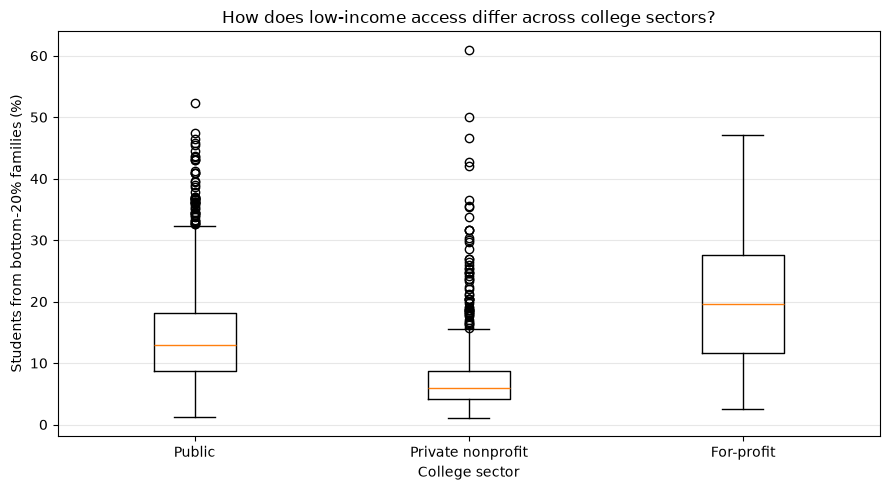

In [13]:
import matplotlib.pyplot as plt

sectors = {1: "Public", 2: "Private nonprofit", 3: "For-profit"}

values = [
    table3.loc[table3["type"] == code, "par_q1"].dropna() * 100
    for code in sectors
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(values)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(sectors.values())

ax.set_title("How does low-income access differ across college sectors?")
ax.set_xlabel("College sector")
ax.set_ylabel("Students from bottom-20% families (%)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("access_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

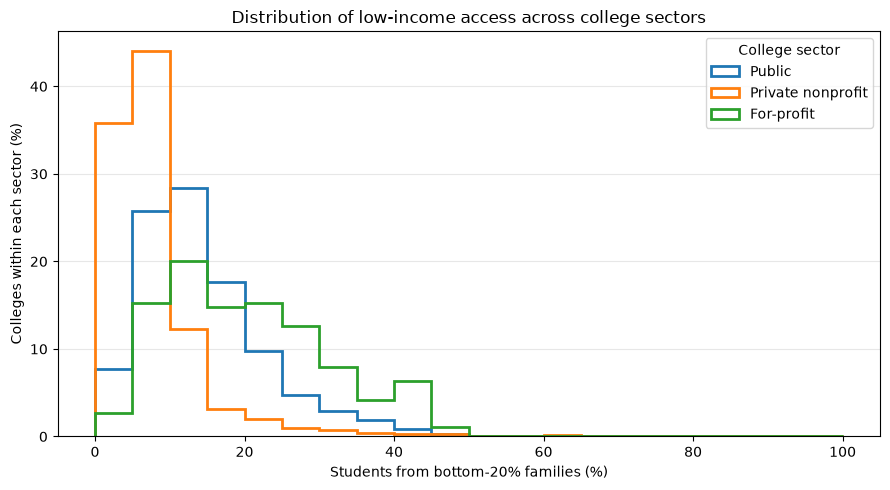

In [14]:
import numpy as np
import matplotlib.pyplot as plt

sectors = {1: "Public", 2: "Private nonprofit", 3: "For-profit"}
bins = np.arange(0, 105, 5)  # Same 5-percentage-point bins for every sector

fig, ax = plt.subplots(figsize=(9, 5))

for code, label in sectors.items():
    values = table3.loc[
        table3["type"] == code, "par_q1"
    ].dropna() * 100

    if len(values) > 0:
        ax.hist(
            values,
            bins=bins,
            weights=np.ones(len(values)) * 100 / len(values),
            histtype="step",
            linewidth=2,
            label=label
        )

ax.set_title("Distribution of low-income access across college sectors")
ax.set_xlabel("Students from bottom-20% families (%)")
ax.set_ylabel("Colleges within each sector (%)")
ax.legend(title="College sector")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("access_histogram.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
table3.to_csv("college_mobility.csv", index=False)